# Лабораторная работа 3. Решающее дерево

Исследуем, насколько точно последовательность пороговых правил определяет тип здания в Эймсе и оценивает в секундах время проверки исхода аукциона. У полного дерева есть риск запомнить редкие комбинации признаков, поэтому сравним его с деревьями ограниченной сложности.

Во всех работах используются одни и те же объекты. Для Ames это 2 344 дома в обучении и 586 в тесте. Определяем принадлежность к классу отдельно стоящих односемейных домов (1 — `1Fam`, 0 — остальные типы). Для Auction Verification это 1 723 запроса в обучении и 320 в тесте. Прогнозируем длительность проверки в секундах на пяти конфигурациях лимитов участников, отсутствующих в обучении. [Постановка задач, источники и разведочный анализ](01_knn.ipynb)

## Данные и разбиение выборки

In [1]:
# Указываем входные признаки и параметры эксперимента.
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SEED = 42
AMES_NUM = [
    "Lot Area", "Lot Frontage", "Year Built", "Overall Qual", "Overall Cond",
    "Gr Liv Area", "1st Flr SF", "2nd Flr SF", "Total Bsmt SF", "Full Bath",
    "Half Bath", "Bedroom AbvGr", "Kitchen AbvGr", "TotRms AbvGrd",
    "Garage Area", "Garage Cars",
]
AMES_CAT = ["Neighborhood", "House Style", "Foundation", "Roof Style"]
CAPACITIES = [f"process.b{i}.capacity" for i in range(1, 5)]
AUCTION_CAT = ["property.product", "property.winner"]
AUCTION_FEATURES = [*CAPACITIES, "property.price", *AUCTION_CAT]
RUNTIME = "verification.time"
TASKS = ("classification", "regression")
TASK_NAME = {"classification": "Классификация", "regression": "Регрессия"}



LAB = 3
ALGORITHM = "Дерево"

In [2]:
# Читаем данные и формируем обучающие, проверочные и тестовые выборки.
@dataclass
class Sample:
    X: pd.DataFrame
    y: np.ndarray
    identifiers: np.ndarray
    train: np.ndarray
    test: np.ndarray
    folds: list
    groups: np.ndarray | None = None


def load_samples():
    """Индексы train/test и индексы фолдов относятся к строкам исходной таблицы."""
    ames = pd.read_csv(ROOT / "data/AmesHousing.csv")
    auction = pd.read_csv(ROOT / "data/auction_verification.csv")
    if not ames["PID"].is_unique:
        raise ValueError("Ожидались уникальные идентификаторы объектов")
    if ames["Bldg Type"].isna().any() or auction[RUNTIME].isna().any():
        raise ValueError("В исходной разметке есть пропуски")
    y = ames["Bldg Type"].eq("1Fam").astype(int).to_numpy()
    X = ames[AMES_NUM + AMES_CAT].copy()
    train, test = train_test_split(
        np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED,
    )
    splits = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    folds = [(train[a], train[b]) for a, b in splits.split(X.iloc[train], y[train])]
    classification = Sample(X, y, ames["PID"].to_numpy(), train, test, folds)

    # Лимиты четырёх участников задают конфигурацию одной модели аукциона.
    X = auction[AUCTION_FEATURES].copy()
    X[AUCTION_CAT] = X[AUCTION_CAT].astype(str)
    y = auction[RUNTIME].to_numpy(dtype=float) / 1000  # из миллисекунд в секунды
    groups = auction.groupby(CAPACITIES, sort=True).ngroup().to_numpy()
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    train, test = next(splitter.split(X, y, groups))
    splits = GroupKFold(n_splits=3, shuffle=True, random_state=SEED)
    folds = [(train[a], train[b]) for a, b in splits.split(X.iloc[train], y[train], groups[train])]
    for a, b in [(train, test), *folds]:
        assert not set(groups[a]) & set(groups[b])
    regression = Sample(X, y, np.arange(1, len(auction) + 1), train, test, folds, groups)
    return {"classification": classification, "regression": regression}



samples = load_samples()

In [3]:
# Формируем признаки и обучаем преобразования внутри каждого разбиения.
def feature_frame(X, task, mode):
    """Построчные преобразования используют только поля конкретного объекта."""
    if mode == "base":
        return X
    if mode != "extra":
        raise ValueError(f"Неизвестный набор признаков {mode}")
    result = X.copy()
    if task == "classification":
        lot = X["Lot Area"].replace(0, np.nan)
        above_ground = X["Gr Liv Area"].replace(0, np.nan)
        result["Жилая площадь / участок"] = X["Gr Liv Area"] / lot
        result["Гараж / жилая площадь"] = X["Garage Area"] / above_ground
    else:
        result["Сумма лимитов"] = X[CAPACITIES].sum(axis=1)
        result["Произведение по лимитам"] = (X[CAPACITIES] + 1).prod(axis=1)
    return result


def design(sample, task, mode, train, evaluate):
    """Обучаем заполнение пропусков, шкалу и словарь категорий внутри каждого разбиения."""
    frame = feature_frame(sample.X, task, mode)
    cats = AMES_CAT if task == "classification" else AUCTION_CAT
    nums = [column for column in frame.columns if column not in cats]
    transformers = [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nums)]
    if cats:
        encoder = make_pipeline(
            SimpleImputer(strategy="constant", fill_value="(пропуск)"),
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        )
        transformers.append(("cat", encoder, cats))
    transform = ColumnTransformer(transformers)
    return transform.fit_transform(frame.iloc[train]), transform.transform(frame.iloc[evaluate])

## Метрики и правила сравнения

В Ames основной показатель — **macro-F1**. Для каждого класса вычисляем гармоническое среднее точности и полноты, затем усредняем два результата с равными весами. Дополнительно приводим **accuracy** (долю верных ответов) и **balanced accuracy** (среднюю полноту классов).

Также рассчитываем **ROC-AUC** по вероятностям класса `1Fam`. Он показывает, насколько хорошо модель ранжирует два класса при разных порогах. Чем ближе ROC-AUC к 1, тем лучше.

В UCI минимизируем **MAE** — среднюю абсолютную ошибку длительности проверки в секундах. **RMSE** сильнее штрафует крупные ошибки. **R²** показывает, насколько хорошо прогнозы объясняют вариацию времени относительно константы, равной среднему значению тестовых целей. У R² возможны и отрицательные значения.

Для подбора используем **три фолда внутри обучения**. В Ames сохраняем доли классов; в UCI все запросы с одинаковыми четырьмя лимитами участников остаются вместе. Сравниваем средние значения macro-F1 и MAE по фолдам. При равенстве с точностью до 10⁻¹² остаётся первая из перечисленных конфигураций. После выбора переобучаем модель на всей обучающей части. Библиотечная и собственная версии получают одинаковые матрицы признаков в каждом режиме.

## Бейзлайн и гипотезы

Сначала ограничим только глубину дерева. Затем при той же глубине увеличим минимальный размер листа, чтобы сгладить оценки по редким объектам. Наконец, при неизменных параметрах проверим расширенные признаки. Для Ames это отношения площадей, которые могут выделить планировку. Для аукциона это сумма четырёх лимитов участников и произведение величин (1 + лимит). Если время зависит от сочетания лимитов, одно пороговое правило по такому признаку может заменить несколько разрезов по отдельным лимитам.

Метка `base` означает исходные признаки. Числовые пропуски заполняются медианой, числовые признаки стандартизуются, категории кодируются индикаторами. Все параметры преобразований оцениваются на обучающей части соответствующего фолда. В режиме `extra` для Ames добавляются отношения жилой площади к площади участка и площади гаража к жилой площади, для аукциона — сумма четырёх лимитов и произведение их увеличенных на единицу значений. Произведение служит приближённым индикатором числа возможных комбинаций загрузки участников.

In [4]:
# Задаём семейство моделей и конфигурации до оценки на тесте.
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

def candidates(task):
    depth = 8 if task == "classification" else 5
    leaf = 4 if task == "classification" else 5
    return [
        {"name": "Полное дерево", "features": "base",
         "params": {"max_depth": None, "min_samples_leaf": 1}},
        {"name": "Лимит глубины", "features": "base",
         "params": {"max_depth": depth, "min_samples_leaf": 1}},
        {"name": "Глубина и размер листа", "features": "base",
         "params": {"max_depth": depth, "min_samples_leaf": leaf}},
        {"name": "Добавлены признаки", "features": "extra",
         "params": {"max_depth": depth, "min_samples_leaf": leaf}},
    ]

def make_model(task, own, params):
    if own:
        return TreeModel(task, random_state=42, **params)
    estimator = DecisionTreeClassifier if task == "classification" else DecisionTreeRegressor
    return estimator(random_state=42, **params)

### Проверка гипотез на обучающих фолдах

В таблицах показаны индивидуальные оценки, среднее, выборочное стандартное отклонение и разность средних относительно базовой строки. Положительная разность полезна для macro-F1, отрицательная — для MAE.

In [5]:
# Задаём основные и дополнительные метрики.
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, r2_score, root_mean_squared_error, roc_auc_score,
)



PRIMARY = {"classification": "macro_f1", "regression": "mae"}
NAMES = {"macro_f1": "macro-F1", "mae": "MAE", "balanced_accuracy": "Balanced accuracy",
         "accuracy": "Accuracy", "roc_auc": "ROC-AUC", "rmse": "RMSE", "r2": "R²"}
IMPLEMENTATION = {"sklearn": "sklearn", "own": "Самостоятельная"}
STAGE = {"base": "Базовая", "selected": "Выбор по CV"}


def scores(task, y, prediction):
    if task == "classification":
        return {
            "macro_f1": f1_score(y, prediction, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y, prediction),
            "accuracy": accuracy_score(y, prediction),
        }
    return {"mae": mean_absolute_error(y, prediction),
            "rmse": root_mean_squared_error(y, prediction), "r2": r2_score(y, prediction)}

In [6]:
# Сравниваем конфигурации на трёх фолдах и выводим результаты.
def tune(samples, candidates, make_model, lab, algorithm):
    """CV только на обучающей выборке. При равенстве остаётся первый кандидат."""
    rows, chosen = [], {}
    for task in TASKS:
        sample = samples[task]
        options = candidates(task)
        matrices = {}
        task_rows = []
        for i, option in enumerate(options):
            mode = option["features"]
            if mode not in matrices:
                matrices[mode] = [design(sample, task, mode, a, b) for a, b in sample.folds]
            values = []
            for (a, b), (X_train, X_valid) in zip(sample.folds, matrices[mode]):
                model = make_model(task, False, option["params"]).fit(X_train, sample.y[a])
                prediction = model.predict(X_valid)
                values.append(scores(task, sample.y[b], prediction)[PRIMARY[task]])
            task_rows.append({
                "lab": lab, "algorithm": algorithm, "task": task,
                "configuration": option["name"], "features": mode,
                "params": json.dumps(option["params"], ensure_ascii=False, sort_keys=True),
                **{f"fold_{j}": value for j, value in enumerate(values, 1)},
                "mean": np.mean(values), "std": np.std(values, ddof=1),
                "selected": False, "base": i == 0,
            })
        means = np.array([row["mean"] for row in task_rows])
        best = max(means) if task == "classification" else min(means)
        idx = int(np.flatnonzero(np.isclose(means, best, atol=1e-12, rtol=0))[0])
        task_rows[idx]["selected"] = True
        chosen[task] = options[idx]
        rows.extend(task_rows)
    return pd.DataFrame(rows), chosen


def show_cv(frame):
    for task in TASKS:
        sub = frame[frame.task.eq(task)].copy()
        primary = NAMES[PRIMARY[task]]
        base = sub.loc[sub.base, "mean"].iloc[0]
        sub["delta"] = sub["mean"] - base
        header = f"{TASK_NAME[task]} · {primary} " + ("↑" if task == "classification" else "↓")
        display(Markdown(f"**{header}**"))
        table = sub[["configuration", "features", "fold_1", "fold_2", "fold_3",
                     "mean", "std", "delta", "selected"]].copy()
        table["selected"] = table["selected"].map({True: "✓", False: ""})
        table.columns = ["Конфигурация", "Признаки", "Фолд 1", "Фолд 2", "Фолд 3",
                         "Среднее", "SD", "Δ к базе", "Выбор"]
        display(table.set_index("Конфигурация").round(4))
        winner = sub[sub.selected].iloc[0]
        print(f"Выбор по среднему значению: {winner.configuration} ({primary} {winner['mean']:.4f}).")

In [7]:
# Отбираем конфигурации только по CV, затем фиксируем выбор для обеих реализаций.
base = {task: candidates(task)[0] for task in TASKS}
cv, selected = tune(samples, candidates, make_model, LAB, ALGORITHM)
show_cv(cv)

**Классификация · macro-F1 ↑**

,Признаки,Фолд 1,Фолд 2,Фолд 3,Среднее,SD,Δ к базе,Выбор
Конфигурация,,,,,,,,
Полное дерево,base,0.8943,0.9088,0.9397,0.9143,0.0232,0.0000,
Лимит глубины,base,0.9280,0.9154,0.9346,0.9260,0.0098,0.0117,
Глубина и размер листа,base,0.9345,0.9214,0.9337,0.9299,0.0073,0.0156,✓
Добавлены признаки,extra,0.9248,0.9169,0.9236,0.9218,0.0043,0.0075,


Выбор по среднему значению: Глубина и размер листа (macro-F1 0.9299).


**Регрессия · MAE ↓**

,Признаки,Фолд 1,Фолд 2,Фолд 3,Среднее,SD,Δ к базе,Выбор
Конфигурация,,,,,,,,
Полное дерево,base,0.4590,0.6851,1.8728,1.0056,0.7595,0.0000,✓
Лимит глубины,base,0.9325,1.6273,2.4167,1.6588,0.7426,0.6532,
Глубина и размер листа,base,0.9493,1.7455,2.5559,1.7502,0.8033,0.7446,
Добавлены признаки,extra,1.5028,1.8821,2.9691,2.1180,0.7610,1.1124,


Выбор по среднему значению: Полное дерево (MAE 1.0056).


## Библиотечная модель на отложенной выборке

Сначала оцениваем базовую модель sklearn, затем модель с конфигурацией, выбранной по CV.

In [8]:
# Считаем и выводим метрики тестовых прогнозов.
def run_test(samples, configurations, make_model, lab, algorithm, implementation, stage):
    records, predictions = [], {}
    for task in TASKS:
        sample, config = samples[task], configurations[task]
        X_train, X_test = design(sample, task, config["features"], sample.train, sample.test)
        model = make_model(task, implementation == "own", config["params"])
        model.fit(X_train, sample.y[sample.train])
        pred = model.predict(X_test)
        auc = {}
        if task == "classification":
            # ROC-AUC оценивает ранжирование по вероятности положительного класса.
            probability = model.predict_proba(X_test)[:, 1]
            auc["roc_auc"] = roc_auc_score(sample.y[sample.test], probability)
        predictions[task] = pred
        records.append({
            "lab": lab, "algorithm": algorithm, "task": task, "implementation": implementation,
            "stage": stage, "configuration": config["name"],
            **scores(task, sample.y[sample.test], pred), **auc,
        })
    return pd.DataFrame(records), predictions


def show_test(results):
    for task in TASKS:
        cols = ["accuracy", "macro_f1", "roc_auc", "balanced_accuracy"] if task == "classification" else ["mae", "rmse", "r2"]
        tab = results.loc[results.task.eq(task), ["implementation", "stage", "configuration", *cols]].copy()
        tab["implementation"] = tab["implementation"].map(IMPLEMENTATION)
        tab["stage"] = tab["stage"].map(STAGE)
        tab = tab.rename(columns={"implementation": "Реализация", "stage": "Режим",
                                  "configuration": "Конфигурация", **NAMES})
        display(Markdown(f"**{TASK_NAME[task]}**"))
        display(tab.set_index(["Реализация", "Режим"]).round(4))

In [9]:
# Обучаем два библиотечных варианта на полном train и сравниваем на одном тесте.
lib_base, _ = run_test(samples, base, make_model, LAB, ALGORITHM, "sklearn", "base")
lib_selected, lib_pred = run_test(samples, selected, make_model, LAB, ALGORITHM, "sklearn", "selected")
show_test(pd.concat([lib_base, lib_selected], ignore_index=True))

**Классификация**

Конфигурация  Accuracy  macro-F1  ROC-AUC  \
Реализация Режим                                                              
sklearn    Базовая               Полное дерево    0.9556    0.9228   0.9262   
           Выбор по CV  Глубина и размер листа    0.9642    0.9354   0.9323   

                        Balanced accuracy  
Реализация Режим                           
sklearn    Базовая                 0.9262  
           Выбор по CV             0.9235

**Регрессия**

Конфигурация     MAE    RMSE      R²
Реализация Режим                                             
sklearn    Базовая      Полное дерево  0.4846  1.0111  0.9882
           Выбор по CV  Полное дерево  0.4846  1.0111  0.9882

## Самостоятельная реализация

В каждом узле собственное дерево перебирает пороги между соседними различными значениями каждого признака. Оно выбирает разрез с максимальным уменьшением взвешенной неоднородности. При регрессии это уменьшение суммы квадратов отклонений. Для меток 0 и 1 дисперсия равна p(1−p), а нечистота Джини равна 2p(1−p), поэтому один и тот же поиск находит оптимальный разрез для обеих задач. Регрессионный лист предсказывает среднее время проверки, классификационный — самый частый класс. При равноценных разрезах выбор признака может отличаться от sklearn.

In [10]:
# Описываем узел дерева и обучение CART.
@dataclass
class Node:
    feature: int = -1
    threshold: float = 0.0
    left: "Node | None" = None
    right: "Node | None" = None
    leaf: int = -1

class TreeModel:
    """Полный перебор порогов между соседними различными значениями признака."""

    def __init__(self, task, max_depth=None, min_samples_leaf=1,
                 max_features=None, random_state=42):
        self.task = task
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim != 2 or X.shape[0] != len(y) or min(X.shape) == 0:
            raise ValueError("Нужна непустая матрица X и один отклик на строку")
        if not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError("Перед обучением заполните пропуски")
        if self.task not in ("classification", "regression"):
            raise ValueError("Неизвестный тип задачи")
        if self.task == "classification" and not np.isin(y, [0, 1]).all():
            raise ValueError("Для классификации закодируйте классы числами 0 и 1")
        if self.min_samples_leaf < 1 or (self.max_depth is not None and self.max_depth < 1):
            raise ValueError("Глубина и минимальный размер листа должны быть положительными")

        self._rng = np.random.default_rng(self.random_state)
        self.n_features_in_ = X.shape[1]
        self._n_candidates = self._feature_count(X.shape[1])
        self.leaf_values_ = []
        self.root_ = self._grow(X, y, depth=0)
        self.leaf_values_ = np.asarray(self.leaf_values_)
        return self

    def _feature_count(self, total):
        if self.max_features is None:
            return total
        if self.max_features == "sqrt":
            return max(1, int(np.sqrt(total)))
        if isinstance(self.max_features, float) and 0 < self.max_features <= 1:
            return max(1, int(self.max_features * total))
        if isinstance(self.max_features, int) and 1 <= self.max_features <= total:
            return self.max_features
        raise ValueError("max_features должен быть None, 'sqrt', числом признаков или долей")

    def _best_split(self, X, y, features):
        # Строки временных массивов соответствуют признакам, столбцы — объектам.
        values = X[:, features].T
        order = np.argsort(values, axis=1, kind="stable")
        ordered = np.take_along_axis(values, order, axis=1)
        left_count = np.arange(1, len(y))
        right_count = len(y) - left_count
        valid = ((ordered[:, :-1] < ordered[:, 1:])
                 & (left_count >= self.min_samples_leaf)
                 & (right_count >= self.min_samples_leaf))
        if not valid.any():
            return None

        # Уменьшение суммы квадратов: n_L*n_R/n * (mean_L - mean_R)^2.
        # Для классов 0/1 уменьшение взвешенной нечистоты Джини пропорционально ему.
        centered = y - y.mean()
        left_sum = np.cumsum(centered[order], axis=1)[:, :-1]
        right_sum = centered.sum() - left_sum
        gap = left_sum / left_count - right_sum / right_count
        gain = (left_count * right_count / len(y)) * gap ** 2
        gain[~valid] = -np.inf
        row, column = np.unravel_index(np.argmax(gain), gain.shape)
        a, b = ordered[row, column:column + 2]
        threshold = a + (b - a) / 2
        if threshold >= b:  # соседние числа могут различаться лишь последним битом
            threshold = a
        return int(features[row]), float(threshold)

    def _grow(self, X, y, depth):
        enough_rows = len(y) >= 2 * self.min_samples_leaf
        within_depth = self.max_depth is None or depth < self.max_depth
        if enough_rows and within_depth and np.any(y != y[0]):
            features = self._rng.permutation(self.n_features_in_)
            split = self._best_split(X, y, features[:self._n_candidates])
            # Как и в случайном лесе sklearn, ищем допустимый разрез, даже
            # если все первые случайно выбранные признаки оказались константами.
            for feature in features[self._n_candidates:]:
                if split is not None:
                    break
                split = self._best_split(X, y, [feature])
            if split is not None:
                feature, threshold = split
                go_left = X[:, feature] <= threshold
                return Node(feature, threshold,
                            self._grow(X[go_left], y[go_left], depth + 1),
                            self._grow(X[~go_left], y[~go_left], depth + 1))

        leaf = len(self.leaf_values_)
        self.leaf_values_.append(float(y.mean()))
        return Node(leaf=leaf)

    def apply(self, X):
        """Для каждого объекта вернуть индекс терминального листа."""
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError("Размерность или значения X не соответствуют обучению")
        leaves = np.empty(len(X), dtype=int)
        pending = [(self.root_, np.arange(len(X)))]
        while pending:
            node, rows = pending.pop()
            if node.leaf >= 0:
                leaves[rows] = node.leaf
                continue
            go_left = X[rows, node.feature] <= node.threshold
            pending.append((node.left, rows[go_left]))
            pending.append((node.right, rows[~go_left]))
        return leaves

    def response(self, X):
        """Доля единиц в листе или среднее значение числовой цели."""
        return self.leaf_values_[self.apply(X)]

    def predict(self, X):
        response = self.response(X)
        if self.task == "classification":
            return (response > 0.5).astype(int)
        return response

    def predict_proba(self, X):
        """Используем долю положительного класса в листе дерева."""
        if self.task != "classification":
            raise ValueError("Вероятности доступны для классификации")
        positive = self.response(X)
        return np.column_stack((1 - positive, positive))


Переносим в собственную модель те же признаки и гиперпараметры. Базовую версию сопоставляем с исходным sklearn, а версию после подбора — с библиотечной при той же настройке.

In [11]:
# Оцениваем собственные модели в двух режимах и сравниваем все четыре варианта.
own_base, _ = run_test(samples, base, make_model, LAB, ALGORITHM, "own", "base")
own_selected, own_pred = run_test(samples, selected, make_model, LAB, ALGORITHM, "own", "selected")
results = pd.concat([lib_base, lib_selected, own_base, own_selected], ignore_index=True)
show_test(results)

**Классификация**

Конфигурация  Accuracy  macro-F1  \
Реализация      Режим                                                     
sklearn         Базовая               Полное дерево    0.9556    0.9228   
                Выбор по CV  Глубина и размер листа    0.9642    0.9354   
Самостоятельная Базовая               Полное дерево    0.9539    0.9202   
                Выбор по CV  Глубина и размер листа    0.9625    0.9321   

                             ROC-AUC  Balanced accuracy  
Реализация      Режим                                    
sklearn         Базовая       0.9262             0.9262  
                Выбор по CV   0.9323             0.9235  
Самостоятельная Базовая       0.9251             0.9251  
                Выбор по CV   0.9332             0.9185

**Регрессия**

Конфигурация     MAE    RMSE      R²
Реализация      Режим                                             
sklearn         Базовая      Полное дерево  0.4846  1.0111  0.9882
                Выбор по CV  Полное дерево  0.4846  1.0111  0.9882
Самостоятельная Базовая      Полное дерево  0.4846  1.0111  0.9882
                Выбор по CV  Полное дерево  0.4846  1.0111  0.9882

## Диагностика ошибок

Строки матрицы соответствуют фактическому типу здания, столбцы — прогнозу. На правом графике точки выше диагонали означают завышение времени, ниже — занижение. Обе панели показывают модель sklearn после подбора.

In [12]:
# Строим матрицу ошибок и сопоставляем прогноз времени с наблюдениями.
def plot_predictions(samples, predictions):
    """Ошибки выбранных библиотечных моделей на общем тесте."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
    s = samples["classification"]
    cm = ConfusionMatrixDisplay.from_predictions(
        s.y[s.test], predictions["classification"], display_labels=["Другие", "1Fam"],
        ax=axes[0], cmap="Blues", colorbar=False, values_format="d",
    )
    cm.ax_.set(title="Ошибки классификации", xlabel="Предсказанный класс", ylabel="Истинный класс")
    s = samples["regression"]
    y, pred = s.y[s.test], predictions["regression"]
    lo, hi = min(y.min(), pred.min()), max(y.max(), pred.max())
    axes[1].plot([lo, hi], [lo, hi], color="#576473", lw=1, ls="--", label="Точный прогноз")
    axes[1].scatter(y, pred, s=23, alpha=.68, color="#126d79", edgecolors="none")
    axes[1].set(title="Время формальной проверки", xlabel="Факт, с",
                ylabel="Прогноз, с", xlim=(lo - 1, hi + 1), ylim=(lo - 1, hi + 1))
    axes[1].legend(frameon=False, loc="upper left", fontsize=9)
    plt.show()

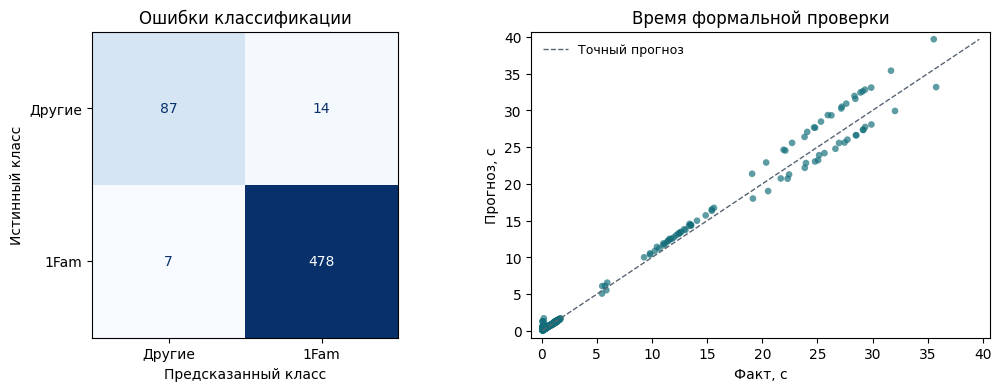

Другие типы, ошибочно отнесённые к 1Fam: 14 из 101.
Классовые прогнозы своей модели и sklearn расходятся на 1 из 586 домов.
Наибольшая абсолютная ошибка sklearn: 4.13 с (факт 35.54, прогноз 39.67, номер наблюдения = 1103).


In [13]:
# Находим ошибки по классам, максимальную ошибку длительности и расхождение реализаций.
plot_predictions(samples, lib_pred)
sample = samples["classification"]
truth = sample.y[sample.test]
missed = ((truth == 0) & (lib_pred["classification"] == 1)).sum()
disagreements = np.sum(lib_pred["classification"] != own_pred["classification"])
print(f"Другие типы, ошибочно отнесённые к 1Fam: {missed} из {(truth == 0).sum()}.")
print(f"Классовые прогнозы своей модели и sklearn расходятся на {disagreements} из {len(truth)} домов.")
sample = samples["regression"]
truth = sample.y[sample.test]
pred = lib_pred["regression"]
idx = np.argmax(np.abs(pred - truth))
print(f"Наибольшая абсолютная ошибка sklearn: {abs(pred[idx] - truth[idx]):.2f} с "
      f"(факт {truth[idx]:.2f}, прогноз {pred[idx]:.2f}, номер наблюдения = {sample.identifiers[sample.test[idx]]}).")

## Выводы

In [14]:
# Сопоставляем реализации и сохраняем результаты в CSV.
def describe(results, cv):
    """Сравниваем стадии у каждой реализации и обе реализации при одинаковых настройках."""
    for task in TASKS:
        metric = PRIMARY[task]
        tab = results[results.task.eq(task)].pivot(index="implementation", columns="stage", values=metric)
        base, selected = tab.loc["sklearn", ["base", "selected"]]
        scratch_base, scratch_selected = tab.loc["own", ["base", "selected"]]
        direction = 1 if task == "classification" else -1
        delta = selected - base
        verdict = "улучшился" if direction * delta > 1e-9 else "ухудшился" if direction * delta < -1e-9 else "не изменился"
        vals = cv[cv.task.eq(task)]
        name = vals.loc[vals.selected, "configuration"].iloc[0]
        text = (f"**{TASK_NAME[task]}.** По CV выбрана конфигурация «{name}». "
                f"На тесте показатель {NAMES[metric]} у sklearn {verdict}: "
                f"{base:.4f} → {selected:.4f}. У собственной реализации: "
                f"{scratch_base:.4f} → {scratch_selected:.4f}. ")
        diff_base, diff_selected = scratch_base - base, scratch_selected - selected
        if max(abs(diff_base), abs(diff_selected)) < 1e-9:
            text += "По этой метрике результаты двух реализаций совпали в обоих режимах."
        else:
            text += (f"Разность «своя минус sklearn» составила {diff_base:+.4f} "
                     f"для базовой и {diff_selected:+.4f} для выбранной настройки.")
        display(Markdown(text))


def save_results(lab, results, cv):
    folder = ROOT / "results"
    folder.mkdir(exist_ok=True)
    results.to_csv(folder / f"lab_{lab}_metrics.csv", index=False)
    cv.to_csv(folder / f"lab_{lab}_cv.csv", index=False)

In [15]:
# Измеряем эффект подбора и сравниваем свои модели с библиотечными в обоих режимах.
describe(results, cv)
save_results(LAB, results, cv)

**Классификация.** По CV выбрана конфигурация «Глубина и размер листа». На тесте показатель macro-F1 у sklearn улучшился: 0.9228 → 0.9354. У собственной реализации: 0.9202 → 0.9321. Разность «своя минус sklearn» составила -0.0027 для базовой и -0.0034 для выбранной настройки.

**Регрессия.** По CV выбрана конфигурация «Полное дерево». На тесте показатель MAE у sklearn не изменился: 0.4846 → 0.4846. У собственной реализации: 0.4846 → 0.4846. По этой метрике результаты двух реализаций совпали в обоих режимах.

Для определения типа здания выиграло ограничение глубины и размера листа. Для времени проверки аукциона CV оставила полное дерево: ограничение глубины подняло MAE с 1,006 до 1,659 с. В этой задаче более мелкие листья позволили различать сочетания параметров запросов.

[Сводное сравнение всех пяти алгоритмов](06_summary.ipynb)